# Sales & Demand Forecasting
## Notebook 4: Model Evaluation

### Objective
Evaluate the performance of the Naive Baseline and Linear Regression models using appropriate regression metrics.

### Scope
- Load the saved model predictions.
- Calculate MAE, RMSE, and R² for both models.
- Compare model performance.
- Identify which model performs better based on the evaluation results.
- Summarize the findings and limitations.

### Next Step
Use the evaluation results to document the project's findings and recommendations.

## 1. Load Model Predictions

Load the predictions saved in Notebook 3. These include the actual sales values and predictions from both models.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Project paths
PROJECT_DIR = Path("..")
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Load model predictions
predictions = pd.read_csv(
    OUTPUT_DIR / "model_predictions.csv",
    parse_dates=["date"]
)

print("Dataset shape:", predictions.shape)
print("\nColumns:", predictions.columns.tolist())
print("\nMissing values:")
print(predictions.isnull().sum())

display(predictions.head())

Dataset shape: (49, 4)

Columns: ['date', 'actual_sales', 'naive_prediction', 'linear_regression_prediction']

Missing values:
date                            0
actual_sales                    0
naive_prediction                0
linear_regression_prediction    0
dtype: int64


,date,actual_sales,naive_prediction,linear_regression_prediction
0,2016-09-11,5.492016e+06,5.750789e+06,5.872551e+06
1,2016-09-18,5.084586e+06,5.750789e+06,5.891177e+06
2,2016-09-25,5.010213e+06,5.750789e+06,5.909803e+06
3,2016-10-02,5.539344e+06,5.750789e+06,5.928430e+06
4,2016-10-09,5.706731e+06,5.750789e+06,5.947056e+06


## 2. Calculate Evaluation Metrics

Evaluate both models using the following regression metrics:

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted sales.
- **RMSE (Root Mean Squared Error):** Penalizes larger prediction errors more heavily.
- **R² Score:** Measures how well the predictions explain variation in actual sales. A higher score is generally better.

In [2]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Actual sales
y_actual = predictions["actual_sales"]

# Naive Baseline metrics
naive_mae = mean_absolute_error(
    y_actual, predictions["naive_prediction"]
)
naive_rmse = np.sqrt(mean_squared_error(
    y_actual, predictions["naive_prediction"]
))
naive_r2 = r2_score(
    y_actual, predictions["naive_prediction"]
)

# Linear Regression metrics
lr_mae = mean_absolute_error(
    y_actual, predictions["linear_regression_prediction"]
)
lr_rmse = np.sqrt(mean_squared_error(
    y_actual, predictions["linear_regression_prediction"]
))
lr_r2 = r2_score(
    y_actual, predictions["linear_regression_prediction"]
)

# Display results
evaluation_results = pd.DataFrame({
    "Model": ["Naive Baseline", "Linear Regression"],
    "MAE": [naive_mae, lr_mae],
    "RMSE": [naive_rmse, lr_rmse],
    "R2 Score": [naive_r2, lr_r2]
})

evaluation_results.round(2)

,Model,MAE,RMSE,R2 Score
0,Naive Baseline,385162.65,523645.65,-0.11
1,Linear Regression,551384.32,637005.79,-0.64


## 3. Model Comparison

The evaluation results show the following:

- **Naive Baseline:** MAE = 385,162.65, RMSE = 523,645.65, R² = -0.11.
- **Linear Regression:** MAE = 551,384.32, RMSE = 637,005.79, R² = -0.64.

The Naive Baseline performed better because it achieved lower MAE and RMSE values and a higher R² score.

Both models produced negative R² scores, indicating that their predictions performed worse than a baseline that predicts the mean of the actual test-period sales.

Linear Regression, using only the continuous time index, did not capture the sales patterns well enough to outperform the Naive Baseline.

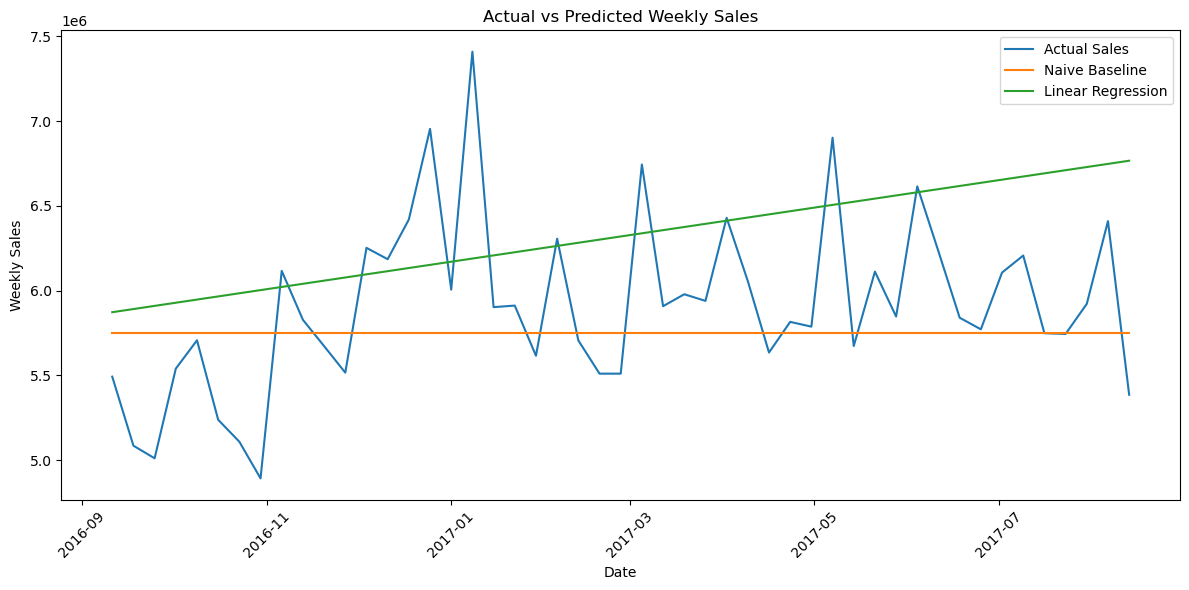

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    predictions["date"],
    predictions["actual_sales"],
    label="Actual Sales"
)

plt.plot(
    predictions["date"],
    predictions["naive_prediction"],
    label="Naive Baseline"
)

plt.plot(
    predictions["date"],
    predictions["linear_regression_prediction"],
    label="Linear Regression"
)

plt.title("Actual vs Predicted Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Model Evaluation Summary

- Evaluated the Naive Baseline and Linear Regression models using MAE, RMSE, and R².
- The Naive Baseline achieved lower MAE (385,162.65) and RMSE (523,645.65) than Linear Regression.
- The Naive Baseline also achieved a higher R² score (-0.11) than Linear Regression (-0.64).
- The comparison chart shows that actual weekly sales fluctuate considerably. The Naive Baseline produces constant predictions, while Linear Regression captures an upward trend but misses many sales fluctuations.
- Both models produced negative R² scores, indicating that neither performed well relative to predicting the mean of the actual test-period sales.

### Conclusion

The Naive Baseline performed better than Linear Regression among the two models tested. However, both models have limitations in capturing weekly sales variation, so forecasting performance needs improvement.

### Next Step

Document the findings and limitations in the project README. Future improvements could include additional time-based features and seasonal patterns.